In [2]:
pip install opencv-python matplotlib numpy scikit-image

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/12.0 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.0 MB 3.3 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/12.0 MB 7.4 MB/s eta 0:00:02
   ------------- -------------------------- 4.2/12.0 MB 7.6 MB/s eta 0:00:02
   ------------------ --------------------- 5.5/12.0 MB 7.0 MB/s eta 0:00:01
   ------------------------ --------------- 7.3/12.0 MB 7.4 MB/s eta 0:00:01
   ---------------------------- ----------- 8.7/12.0 MB 7.4 MB/s eta 0:00:01
   ---------------------------------- ----- 10.5/12.0 MB 7.3 MB/s eta 0:00:01
   ---------------------------------------- 12.0/12.0 MB 7.3 MB/s  0:00:01
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------  2.1/2.1 MB 10.4 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 9.5 MB/s  0:00:00
   ---------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


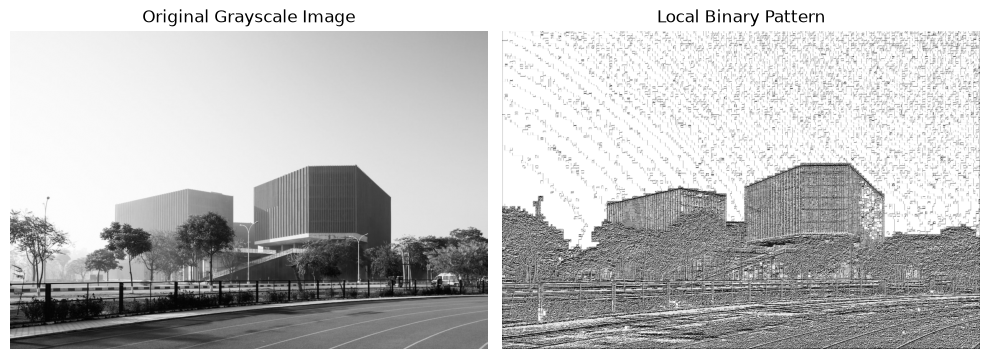

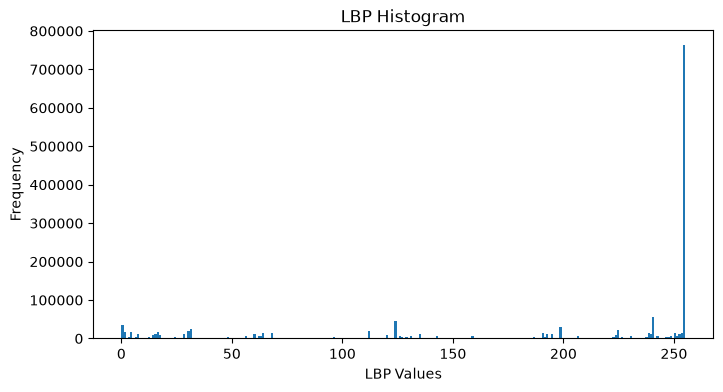

In [3]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

# Read grayscale image
img = cv2.imread('image.jpg', 0)

# Check image
if img is None:
    raise ValueError("Image not found!")

# LBP parameters
radius = 1
points = 8 * radius

# Apply Local Binary Pattern
lbp = local_binary_pattern(
    img, points, radius, method='default'
)

# Display original and LBP images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title('Local Binary Pattern')
plt.axis('off')

plt.tight_layout()
plt.show()

# Plot LBP histogram
plt.figure(figsize=(8, 4))
plt.hist(lbp.ravel(), bins=256)
plt.title('LBP Histogram')
plt.xlabel('LBP Values')
plt.ylabel('Frequency')
plt.show()


In [4]:
pip install opencv-python matplotlib numpy scipy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


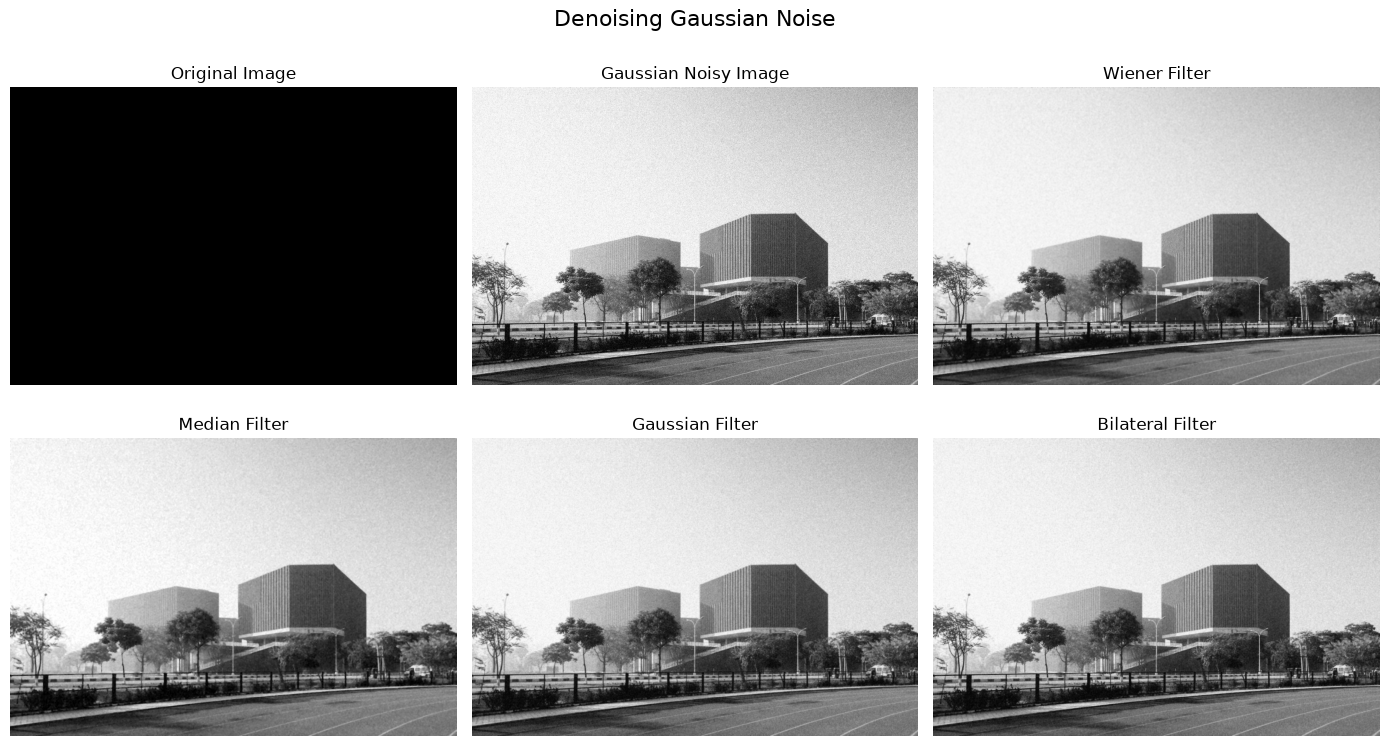

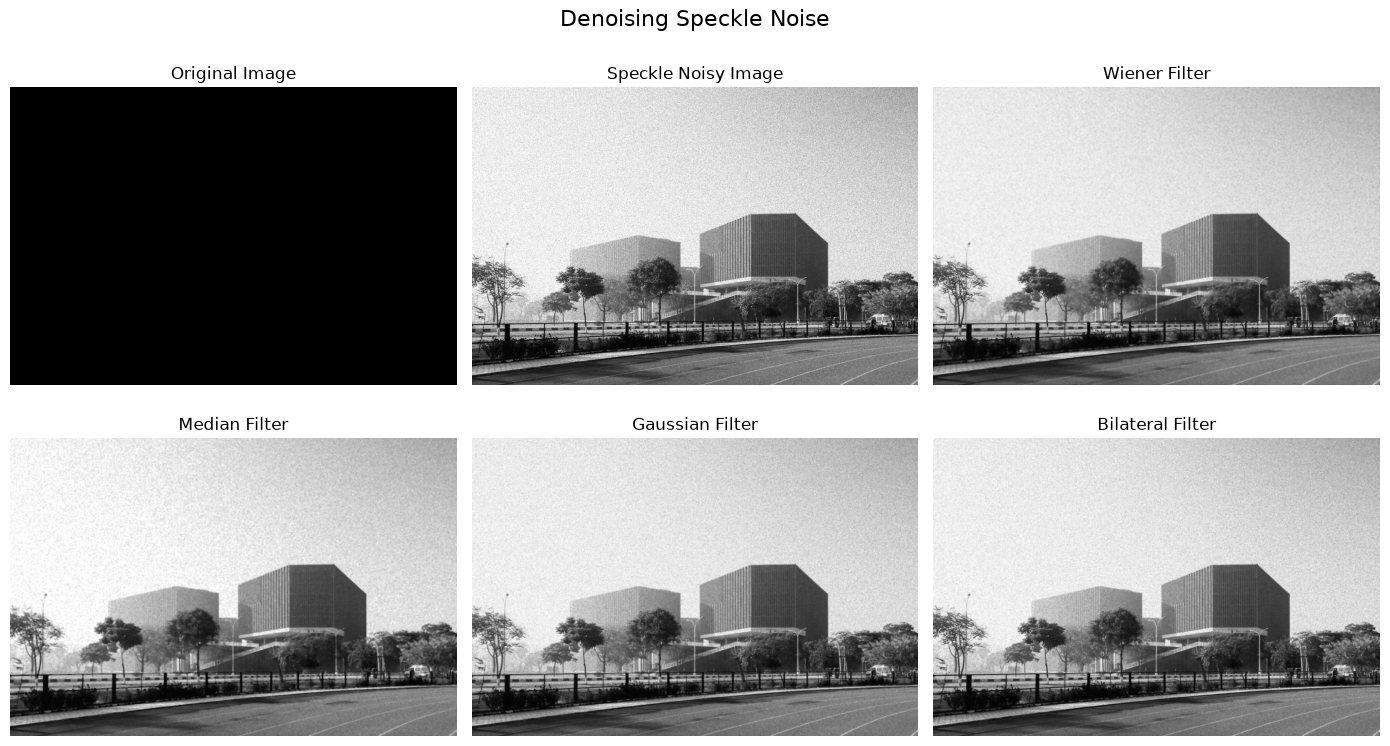

Image denoising completed successfully!


In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener

# Read grayscale image
img = cv2.imread('image.jpg', 0)

if img is None:
    raise ValueError("Image not found!")

# Convert image to float (0 to 1)
img = img.astype(np.float32) / 255.0

# Generate Gaussian noise
gaussian_noise = np.random.normal(0, 0.08, img.shape)
gaussian_img = np.clip(img + gaussian_noise, 0, 1)

# Generate Speckle noise
speckle_noise = np.random.normal(0, 0.15, img.shape)
speckle_img = np.clip(img + img * speckle_noise, 0, 1)

# Convert noisy images to uint8
gaussian_img = (gaussian_img * 255).astype(np.uint8)
speckle_img = (speckle_img * 255).astype(np.uint8)

# Function to apply filters
def apply_filters(noisy_img):

    # (a) Wiener Filter
    wiener_img = wiener(noisy_img.astype(np.float32),
                        mysize=(5, 5))
    wiener_img = np.clip(wiener_img, 0, 255).astype(np.uint8)

    # (b) Median Filter
    median_img = cv2.medianBlur(noisy_img, 5)

    # (c) Gaussian Filter
    gaussian_filtered = cv2.GaussianBlur(
        noisy_img, (5, 5), 0
    )

    # (d) Bilateral Filter
    bilateral_img = cv2.bilateralFilter(
        noisy_img, 5, 75, 75
    )

    return wiener_img, median_img, gaussian_filtered, bilateral_img


# Apply filters to Gaussian noisy image
g_wiener, g_median, g_gaussian, g_bilateral = apply_filters(gaussian_img)

# Apply filters to Speckle noisy image
s_wiener, s_median, s_gaussian, s_bilateral = apply_filters(speckle_img)


# Display Gaussian noise results
images1 = [
    img, gaussian_img, g_wiener,
    g_median, g_gaussian, g_bilateral
]

titles1 = [
    'Original Image',
    'Gaussian Noisy Image',
    'Wiener Filter',
    'Median Filter',
    'Gaussian Filter',
    'Bilateral Filter'
]

plt.figure(figsize=(14, 8))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images1[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles1[i])
    plt.axis('off')

plt.suptitle('Denoising Gaussian Noise', fontsize=16)
plt.tight_layout()
plt.show()


# Display Speckle noise results
images2 = [
    img, speckle_img, s_wiener,
    s_median, s_gaussian, s_bilateral
]

titles2 = [
    'Original Image',
    'Speckle Noisy Image',
    'Wiener Filter',
    'Median Filter',
    'Gaussian Filter',
    'Bilateral Filter'
]

plt.figure(figsize=(14, 8))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images2[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles2[i])
    plt.axis('off')

plt.suptitle('Denoising Speckle Noise', fontsize=16)
plt.tight_layout()
plt.show()

print("Image denoising completed successfully!")
